# Phase I (Human): How does the model perform the task?

## Setup

In [5]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import PercentFormatter

## Data

In [6]:
ROOT = Path.cwd().parent

df = pd.read_csv(ROOT / "data" / "pure_clean.csv")
split = pd.read_csv(ROOT / "data" / "PURE_seed42.csv")
predictions = pd.read_csv(
    ROOT / "results" / "roberta-pure-seed42" / "test_predictions.csv"
)
df.head()

,instance_id,source_file,requirement_text,label,reasons
0,PURE_000001,0000 - cctns.pdf,Registration Citizens can register their compl...,1,"vague_term,weak_modal"
1,PURE_000002,0000 - cctns.pdf,The solution should provide detailed context-s...,1,weak_modal
2,PURE_000003,0000 - cctns.pdf,The help should be accessible to the users bot...,1,weak_modal
3,PURE_000004,0000 - cctns.pdf,The solution should provide an interface for t...,1,"weak_modal,multiple_actions"
4,PURE_000005,0000 - cctns.pdf,"The solution should send alerts (e.g., email, ...",1,weak_modal


## Visualizations

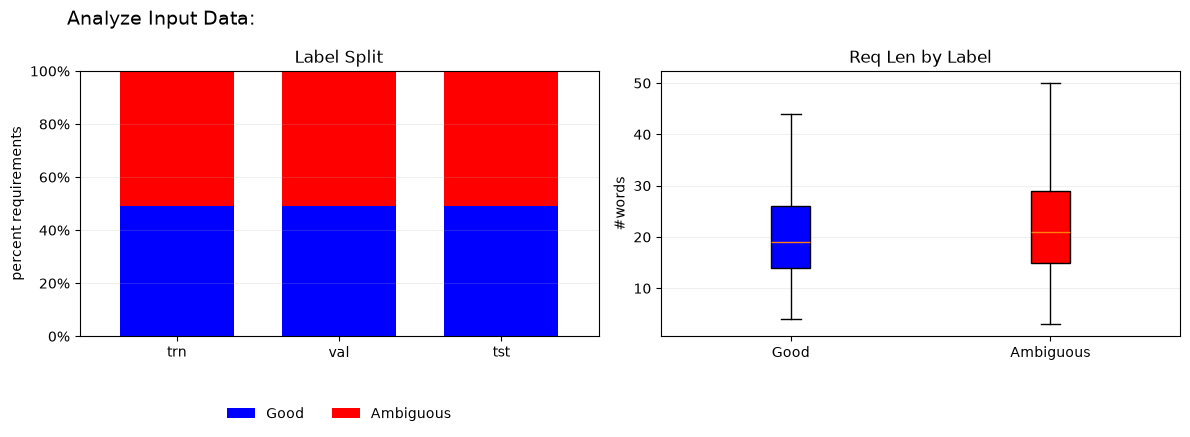

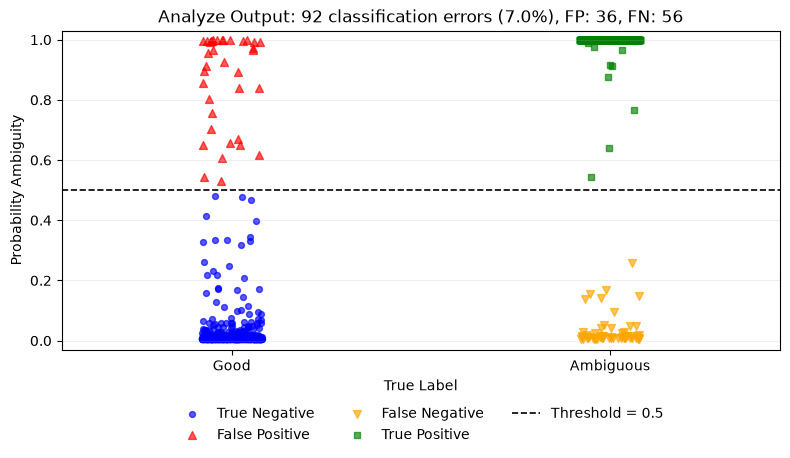

In [7]:
data = pd.merge(
    df,
    split[["instance_id", "split"]],
    on="instance_id",
)
data["word_count"] = data["requirement_text"].str.split().str.len()

split_order = ["train", "validation", "test"]
labels = [0, 1]
colors = ["blue", "red"]

label_mix = pd.crosstab(data["split"], data["label"], normalize="index")
label_mix = label_mix.reindex(index=split_order, columns=labels)
label_mix.index = ["trn", "val", "tst"]
label_mix.columns = ["Good", "Ambiguous"]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
label_mix.plot.bar(stacked=True, color=colors, ax=axes[0], width=0.7)
axes[0].set_title("Label Split")
axes[0].set_ylabel("percent requirements")
axes[0].set_ylim(0, 1)
axes[0].yaxis.set_major_formatter(PercentFormatter(1))
axes[0].tick_params(axis="x", labelrotation=0)
axes[0].grid(axis="y", alpha=0.2)
axes[0].legend(
    frameon=False,
    loc="upper center",
    bbox_to_anchor=(0.5, -0.22),
    ncol=2,
)

clear_words = data.loc[data["label"] == 0, "word_count"]
ambiguous_words = data.loc[data["label"] == 1, "word_count"]
axes[1].boxplot(
    [clear_words, ambiguous_words],
    tick_labels=["Good", "Ambiguous"],
    patch_artist=True,
    showfliers=False,
)
axes[1].patches[0].set_facecolor("blue")
axes[1].patches[1].set_facecolor("red")
axes[1].set_title("Req Len by Label")
axes[1].set_ylabel("#words")
axes[1].grid(axis="y", alpha=0.2)

fig.suptitle("Analyze Input Data:", x=0.06, ha="left", fontsize=14)
fig.tight_layout()
fig.subplots_adjust(bottom=0.3)
plt.show()

true_labels = predictions["true_label"].to_numpy()
predicted_labels = predictions["predicted_label"].to_numpy()
true_negative = (true_labels == 0) & (predicted_labels == 0)
false_positive = (true_labels == 0) & (predicted_labels == 1)
false_negative = (true_labels == 1) & (predicted_labels == 0)
true_positive = (true_labels == 1) & (predicted_labels == 1)

error_count = false_positive.sum() + false_negative.sum()
error_rate = error_count / len(predictions)
np.random.seed(42)
x = true_labels + np.random.uniform(-0.08, 0.08, len(true_labels))

fig, ax = plt.subplots(figsize=(8, 5.5))
ax.scatter(
    x[true_negative],
    predictions.loc[true_negative, "probability_ambiguous"],
    color="blue",
    marker="o",
    s=18,
    alpha=0.65,
    label="True Negative",
)
ax.scatter(
    x[false_positive],
    predictions.loc[false_positive, "probability_ambiguous"],
    color="red",
    marker="^",
    s=32,
    alpha=0.65,
    label="False Positive",
)
ax.scatter(
    x[false_negative],
    predictions.loc[false_negative, "probability_ambiguous"],
    color="orange",
    marker="v",
    s=32,
    alpha=0.65,
    label="False Negative",
)
ax.scatter(
    x[true_positive],
    predictions.loc[true_positive, "probability_ambiguous"],
    color="green",
    marker="s",
    s=18,
    alpha=0.65,
    label="True Positive",
)
ax.axhline(
    0.5,
    color="black",
    linestyle="--",
    linewidth=1.2,
    label="Threshold = 0.5",
)
ax.set_title(
    f"Analyze Output: {error_count} classification errors "
    f"({error_rate:.1%}), FP: {false_positive.sum()}, "
    f"FN: {false_negative.sum()}"
)
ax.set_xlabel("True Label")
ax.set_ylabel("Probability Ambiguity")
ax.set_xlim(-0.45, 1.45)
ax.set_ylim(-0.03, 1.03)
ax.set_xticks(labels, ["Good", "Ambiguous"])
ax.grid(axis="y", alpha=0.2)
ax.legend(
    frameon=False,
    loc="upper center",
    bbox_to_anchor=(0.5, -0.14),
    ncol=3,
)
fig.tight_layout()
fig.subplots_adjust(bottom=0.25, top=0.83)
plt.show()

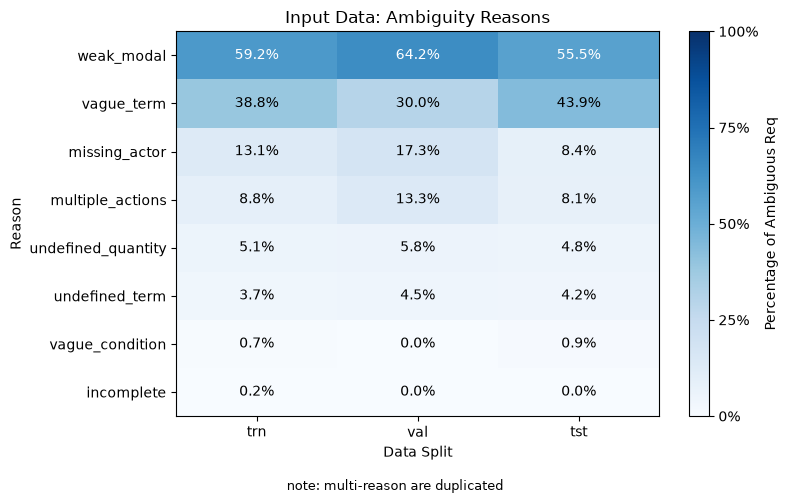

In [8]:
input_reasons = df[df["label"] == 1][["instance_id", "reasons"]].copy()
input_reasons = input_reasons.merge(
    split[["instance_id", "split"]],
    on="instance_id",
)

split_names = ["train", "validation", "test"]
ambiguous_by_split = input_reasons["split"].value_counts()
ambiguous_by_split = ambiguous_by_split.reindex(split_names)

input_reasons["reason"] = input_reasons["reasons"].fillna("").str.split(",")
input_reasons = input_reasons.explode("reason")
input_reasons["reason"] = input_reasons["reason"].str.strip()
input_reasons = input_reasons[input_reasons["reason"] != ""]

input_reason_counts = pd.crosstab(
    input_reasons["reason"], input_reasons["split"]
)
input_reason_counts = input_reason_counts.reindex(
    columns=split_names,
    fill_value=0,
)
input_reason_counts["total"] = input_reason_counts.sum(axis=1)
input_reason_counts = input_reason_counts.sort_values("total", ascending=False)
input_reason_counts = input_reason_counts.drop(columns="total")

input_reason_rates = input_reason_counts.astype(float)
for reason in input_reason_counts.index:
    for split_name in split_names:
        input_reason_rates.loc[reason, split_name] = (
            input_reason_counts.loc[reason, split_name]
            / ambiguous_by_split[split_name]
        )

fig, ax = plt.subplots(figsize=(8, 5))
image = ax.imshow(input_reason_rates, cmap="Blues", vmin=0, vmax=1, aspect="auto")
ax.set_xticks([0, 1, 2], ["trn", "val", "tst"])
ax.set_yticks(range(len(input_reason_rates)), input_reason_rates.index)
ax.set_title("Input Data: Ambiguity Reasons")
ax.set_xlabel("Data Split")
ax.set_ylabel("Reason")

for row in range(len(input_reason_rates)):
    for column in range(3):
        percentage = input_reason_rates.iloc[row, column]
        if percentage >= 0.55:
            text_color = "white"
        else:
            text_color = "black"
        ax.text(
            column,
            row,
            f"{percentage:.1%}",
            ha="center",
            va="center",
            color=text_color,
        )

colorbar = fig.colorbar(image, ax=ax, ticks=[0, 0.25, 0.5, 0.75, 1])
colorbar.ax.yaxis.set_major_formatter(PercentFormatter(1))
colorbar.set_label("Percentage of Ambiguous Req")
fig.text(
    0.5,
    0.01,
    "note: multi-reason are duplicated",
    ha="center",
    fontsize=9,
)
fig.tight_layout(rect=(0, 0.04, 1, 1))
plt.show()

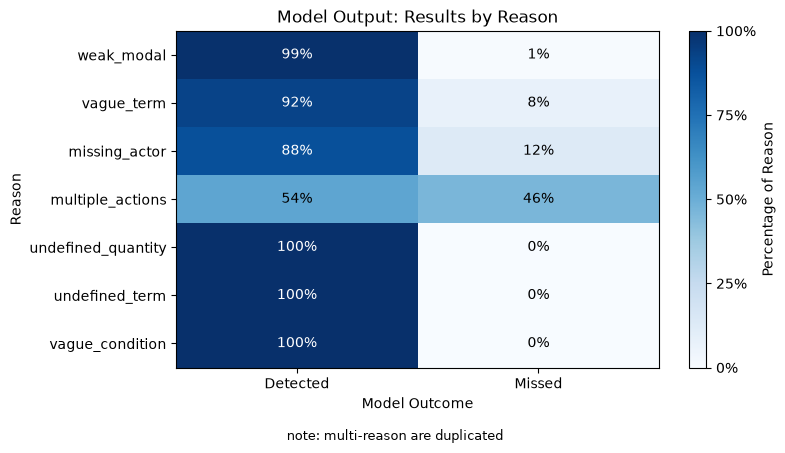

In [9]:
ambiguous_test = predictions[predictions["true_label"] == 1].copy()
reason_rows = ambiguous_test[["reasons", "predicted_label"]].copy()
reason_rows["reason"] = reason_rows["reasons"].fillna("").str.split(",")
reason_rows = reason_rows.explode("reason")
reason_rows["reason"] = reason_rows["reason"].str.strip()
reason_rows = reason_rows[reason_rows["reason"] != ""]

reason_rows["outcome"] = "Detected"
reason_rows.loc[reason_rows["predicted_label"] == 0, "outcome"] = "Missed"

reason_counts = pd.crosstab(reason_rows["reason"], reason_rows["outcome"])
reason_counts = reason_counts.reindex(columns=["Detected", "Missed"], fill_value=0)
reason_counts["total"] = reason_counts.sum(axis=1)
reason_counts = reason_counts.sort_values("total", ascending=False)
reason_counts = reason_counts[["Detected", "Missed"]]

reason_rates = reason_counts.astype(float)
for reason in reason_counts.index:
    total = reason_counts.loc[reason].sum()
    reason_rates.loc[reason] = reason_counts.loc[reason] / total

fig, ax = plt.subplots(figsize=(8, 4.5))
image = ax.imshow(reason_rates, cmap="Blues", vmin=0, vmax=1, aspect="auto")
ax.set_xticks([0, 1], ["Detected", "Missed"])
ax.set_yticks(range(len(reason_rates)), reason_rates.index)
ax.set_title("Model Output: Results by Reason")
ax.set_xlabel("Model Outcome")
ax.set_ylabel("Reason")

for row in range(len(reason_rates)):
    for column in range(2):
        percentage = reason_rates.iloc[row, column]
        if percentage >= 0.65:
            text_color = "white"
        else:
            text_color = "black"
        ax.text(
            column,
            row,
            f"{percentage:.0%}",
            ha="center",
            va="center",
            color=text_color,
        )

colorbar = fig.colorbar(image, ax=ax, ticks=[0, 0.25, 0.5, 0.75, 1])
colorbar.ax.yaxis.set_major_formatter(PercentFormatter(1))
colorbar.set_label("Percentage of Reason")
fig.text(
    0.5,
    0.01,
    "note: multi-reason are duplicated",
    ha="center",
    fontsize=9,
)
fig.tight_layout(rect=(0, 0.04, 1, 1))
plt.show()

## Notes and Findings